# Momento 1 Convolución

In [43]:
import numpy as np
import tensorflow as tf

def funcion_convolucion(matriz_mxm, kernel, padding):
    # 1. Validar que la matriz es cuadrada (m x m)
    matriz_mxm = np.array(matriz_mxm)
    if matriz_mxm.shape[0] != matriz_mxm.shape[1]:
        raise ValueError("La matriz de entrada debe ser cuadrada (m x m).")

    m = matriz_mxm.shape[0]

    # 2. Validar que el kernel es cuadrado (n x n), con n positivo
    if not (isinstance(kernel, tuple) and len(kernel) == 2 and kernel[0] == kernel[1] and kernel[0] > 0):
        raise ValueError("El kernel debe ser cuadrado (n x n) con dimensiones positivas.")

    n = kernel[0]
    def kernel_initializer(shape=kernel, dtype=np.int32):
      return tf.keras.random.normal(shape, dtype=dtype)

    # 3. Valiar que el tamaño del kernel es menor que el tamaño de la matriz (n < m)
    if n >= m:
        raise ValueError("El tamaño del kernel (n) debe ser estrictamente menor que el tamaño de la matriz (m).")

    # Preparar la entrada para la Conv2D: reshape a (1, m, m, 1)
    input_tensor = tf.reshape(tf.convert_to_tensor(matriz_mxm, dtype=tf.int32), (1, m, m, 1))

    # Definir la input layer con la forma de una sola matriz (se excluye el tamaño del batch)
    input_layer = tf.keras.layers.Input(shape=input_tensor.shape[1:], name='input_cnn')

    # Creación de un modelo simple. Se usa la función linear para no cambiar los valores
    conv_layer = tf.keras.layers.Conv2D(filters=1,kernel_size=kernel, kernel_initializer=kernel_initializer, activation='linear', padding=padding, use_bias=False)

    # Obtener un tensor para la salida
    output_tensor = conv_layer(input_layer)
    model = tf.keras.Model(inputs=input_layer, outputs=output_tensor)

    # Para obtener los valores de la matriz resultante, se debe hacer una predicción
    convolved_matrix_raw = model.predict(input_tensor, verbose=0)

    # Se eliminan las dimensiones del batch y del canal del tensor para una mejor visualización
    convolved_matrix = convolved_matrix_raw[0, :, :, 0]

    print('Matriz de entrada (original):\n', matriz_mxm)
    print('Dimensión de la matriz de entrada:', matriz_mxm.shape)
    print('Kernel:', kernel)
    print('Padding:', padding)
    print('Matriz resultante de la convolución:\n', convolved_matrix)
    print('Dimensión de la matriz resultante (TensorFlow):', convolved_matrix_raw.shape)
    print('Dimensión de la matriz resultante (Vista simplificada):', convolved_matrix.shape)
    print("-" * 30)


In [44]:
# --- Ejemplos para probar funcion_convolucion ---

# 1. Ejemplo Padding 'valid': Matriz 5x5 con kernel 3x3
print("\n--- Caso de prueba 1: Válido (Matriz 5x5, Kernel 3x3, padding='valid') ---")
matriz_5x5 = np.array([
    [1, 1, 1, 0, 0],
    [0, 1, 1, 1, 0],
    [0, 0, 1, 1, 1],
    [0, 0, 1, 1, 0],
    [0, 1, 1, 0, 0]
])
kernel_3x3 = (3, 3)
funcion_convolucion(matriz_5x5, kernel_3x3, 'valid')

# 2. Ejemplo Padding 'same': Matriz 5x5 con kernel 3x3
print("\n--- Caso de prueba 2: Válido (Matriz 5x5, Kernel 3x3, padding='same') ---")
# matriz_6x6 = np.arange(1, 37).reshape(6, 6)
# kernel_2x2 = (2, 2)
funcion_convolucion(matriz_5x5, kernel_3x3, 'same')




--- Caso de prueba 1: Válido (Matriz 5x5, Kernel 3x3, padding='valid') ---
Matriz de entrada (original):
 [[1 1 1 0 0]
 [0 1 1 1 0]
 [0 0 1 1 1]
 [0 0 1 1 0]
 [0 1 1 0 0]]
Dimensión de la matriz de entrada: (5, 5)
Kernel: (3, 3)
Padding: valid
Matriz resultante de la convolución:
 [[-0.94396734  1.2901378   2.1190393 ]
 [-1.3601706  -1.6086407   0.6581331 ]
 [-2.533696   -1.3569798   1.2972047 ]]
Dimensión de la matriz resultante (TensorFlow): (1, 3, 3, 1)
Dimensión de la matriz resultante (Vista simplificada): (3, 3)
------------------------------

--- Caso de prueba 2: Válido (Matriz 5x5, Kernel 3x3, padding='same') ---
Matriz de entrada (original):
 [[1 1 1 0 0]
 [0 1 1 1 0]
 [0 0 1 1 1]
 [0 0 1 1 0]
 [0 1 1 0 0]]
Dimensión de la matriz de entrada: (5, 5)
Kernel: (3, 3)
Padding: same
Matriz resultante de la convolución:
 [[-0.7747252  -0.29648376 -2.711308   -1.9226063  -2.4008477 ]
 [-0.4006107  -1.237964   -0.35064065 -2.7599597  -1.9226063 ]
 [-0.40908203 -1.4658172  -1.7184782 

# Momento 2: Transfer learning

In [45]:
# 1. Configuración del entorno en Google Colab
# Instalar la API de Kaggle si aún no está instalada
!pip install kaggle -q

# Subir credenciales de Kaggle
from google.colab import files
files.upload()  # Cargar kaggle.json desde tu computadora

# Configurar Kaggle
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle (3).json


In [46]:
# 2. Descargar el dataset desde Kaggle
# Reemplazar '<nombre-del-dataset>' por el nombre del dataset que quieres usar
# !kaggle datasets download -d phucthaiv02/butterfly-image-classification
!kaggle datasets download -d samuelcortinhas/cats-and-dogs-image-classification

# Descomprimir los archivos
!unzip cats-and-dogs-image-classification.zip -d dataset

Dataset URL: https://www.kaggle.com/datasets/samuelcortinhas/cats-and-dogs-image-classification
License(s): CC0-1.0
cats-and-dogs-image-classification.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  cats-and-dogs-image-classification.zip
replace dataset/test/cats/cat_1.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
  inflating: dataset/test/cats/cat_1.jpg  
  inflating: dataset/test/cats/cat_106.jpg  
  inflating: dataset/test/cats/cat_109.jpg  
  inflating: dataset/test/cats/cat_113.jpg  
  inflating: dataset/test/cats/cat_114.jpg  
  inflating: dataset/test/cats/cat_116.jpg  
  inflating: dataset/test/cats/cat_118.jpg  
  inflating: dataset/test/cats/cat_119.jpg  
  inflating: dataset/test/cats/cat_124.jpg  
  inflating: dataset/test/cats/cat_140.jpg  
  inflating: dataset/test/cats/cat_147.jpg  
  inflating: dataset/test/cats/cat_156.jpg  
  inflating: dataset/test/cats/cat_158.jpg  
  inflating: dataset/test/cats/cat_162.jpg  
  inflat

In [47]:
# 3. Importar librerías necesarias
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16, InceptionV3, MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
import matplotlib.pyplot as plt
import numpy as np

# 4. Configuración del preprocesamiento de imágenes
img_size = (224, 224)
batch_size = 32

# Generadores de imágenes con aumento de datos
datagen = ImageDataGenerator(
    rescale=1.0/255, #Reescala los valores, normalizando los valores de los píxeles
    validation_split=0.2,  # División en entrenamiento y validación
    horizontal_flip=True,
    rotation_range=20,
    zoom_range=0.2
)

# Cargar datos
train_data = datagen.flow_from_directory(
    "dataset/train",
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    subset="training"
)

val_data = datagen.flow_from_directory(
    "dataset/test",
    target_size=img_size,
    batch_size=batch_size,
    class_mode="categorical",
    subset="validation"
)

Found 447 images belonging to 2 classes.
Found 28 images belonging to 2 classes.


train_images.image_shape: (224, 224, 3), de tipo float32
test_images.image_shape: (224, 224, 3), de tipo float32
train_images.class_indices: {'cats': 0, 'dogs': 1}


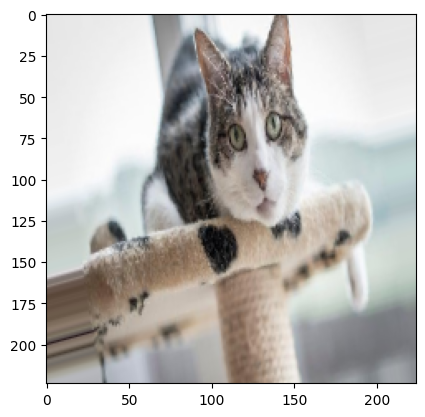

In [48]:
# Exploracion de las imágenes
print('train_images.image_shape: {}, de tipo {}'.format(train_data.image_shape, train_data.dtype))
print('test_images.image_shape: {}, de tipo {}'.format(val_data.image_shape, val_data.dtype))
print('train_images.class_indices: {}'.format(train_data.class_indices))

plt.imshow(train_data[0][0][0])


In [49]:
matriz = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
matriz.shape

(3, 3)

## Usando VGG16

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 18s 715ms/step - accuracy: 0.5850 - loss: 2.7687 - val_accuracy: 0.8929 - val_loss: 0.2794
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 14s 639ms/step - accuracy: 0.7674 - loss: 0.7249 - val_accuracy: 0.8571 - val_loss: 0.3019
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 527ms/step - accuracy: 0.8402 - loss: 0.4128 - val_accuracy: 0.7857 - val_loss: 0.3159
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 591ms/step - accuracy: 0.9055 - loss: 0.2416 - val_accuracy: 0.7857 - val_loss: 0.3616
Epoch 5/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 577ms/step - accuracy: 0.9069 - loss: 0.2147 - val_accuracy: 0.7143 - val_loss: 0.4857
Epoch 6/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 533ms/step - accuracy: 0.8788 - loss: 0.2676 - val_accuracy: 0.8214 - val_loss: 0.2979
Epoch 7/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 579ms/step - accuracy: 0.9129 - loss: 0.2386 - val_accuracy: 0.9286 - val_loss: 0.2892
Epoch 8/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 9s 610ms/step - accuracy: 0.9329 - loss: 0.1871 - val_accuracy: 

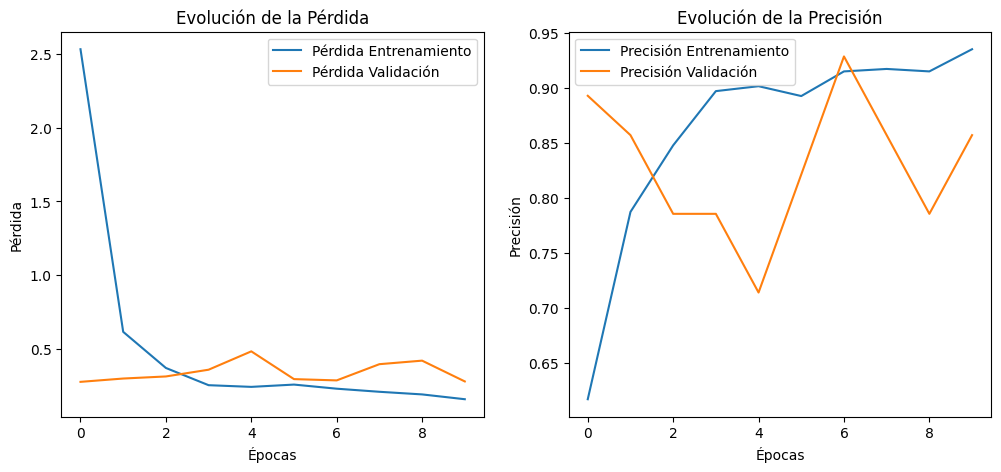

In [50]:
# 5. Cargar el modelo preentrenado VGG16 sin la capa de clasificación
base_model = VGG16(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

# Congelar las capas convolucionales del modelo base
for layer in base_model.layers:
    layer.trainable = False

# Construcción del nuevo modelo con capas personalizadas
model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(len(train_data.class_indices), activation="softmax")  # Ajustar según el número de clases
])

# 6. Compilar el modelo
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# 7. Entrenar el modelo
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

# 8. Evaluar el modelo en el conjunto de validación
test_loss, test_acc = model.evaluate(val_data)
acc_vgg16 = test_acc
print(f"Precisión en validación VGG16: {test_acc:.4f}")

# 9. Visualizar la evolución del entrenamiento
plt.figure(figsize=(12, 5))

# Pérdida
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Pérdida Entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida Validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.title('Evolución de la Pérdida')
plt.legend()

# Precisión
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Precisión Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Precisión Validación')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.title('Evolución de la Precisión')
plt.legend()

plt.show()


## Usando InceptionV3

Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.6460 - loss: 11.2853 - val_accuracy: 0.9643 - val_loss: 0.3663
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - accuracy: 0.9283 - loss: 1.5837 - val_accuracy: 1.0000 - val_loss: 9.8149e-05
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 487ms/step - accuracy: 0.9658 - loss: 0.8001 - val_accuracy: 0.9286 - val_loss: 2.6036
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 541ms/step - accuracy: 0.9581 - loss: 0.6690 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 499ms/step - accuracy: 0.9680 - loss: 0.5838 - val_accuracy: 1.0000 - val_loss: 7.3258e-04
Epoch 6/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 553ms/step - accuracy: 0.9641 - loss: 0.9838 - val_accuracy: 0.8571 - val_loss: 1.9261
Epoch 7/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 558ms/step - accuracy: 0.9837 - loss: 0.1447 - val_accuracy: 0.9643 - val_loss: 0.9582
Epoch 8/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 492ms/step - accuracy: 0.9748 - loss: 0.2920 - val_a

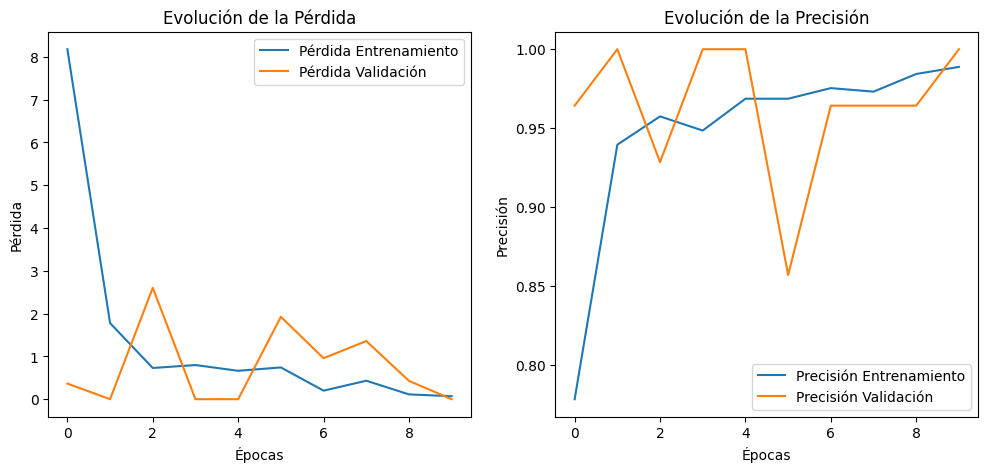

In [51]:
# 5. Cargar el modelo preentrenado sin la capa de clasificación
base_model = InceptionV3(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

# Congelar las capas convolucionales del modelo base
for layer in base_model.layers:
    layer.trainable = False

# Construcción del nuevo modelo con capas personalizadas
model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(len(train_data.class_indices), activation="softmax")  # Ajustar según el número de clases
])

# 6. Compilar el modelo
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# 7. Entrenar el modelo
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

# 8. Evaluar el modelo en el conjunto de validación
test_loss, test_acc = model.evaluate(val_data)
acc_inceptionv3 = test_acc
print(f"Precisión en validación InceptionV3: {test_acc:.4f}")

# 9. Visualizar la evolución del entrenamiento
plt.figure(figsize=(12, 5))

# Pérdida
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Pérdida Entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida Validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.title('Evolución de la Pérdida')
plt.legend()

# Precisión
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Precisión Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Precisión Validación')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.title('Evolución de la Precisión')
plt.legend()

plt.show()


## Usando MobileNetV2

Epoch 1/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.7691 - loss: 3.7651 - val_accuracy: 1.0000 - val_loss: 0.0210
Epoch 2/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 469ms/step - accuracy: 0.9007 - loss: 3.2731 - val_accuracy: 0.9643 - val_loss: 0.7041
Epoch 3/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 539ms/step - accuracy: 0.9367 - loss: 2.0878 - val_accuracy: 0.9286 - val_loss: 3.7734
Epoch 4/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 486ms/step - accuracy: 0.9659 - loss: 1.0272 - val_accuracy: 0.9286 - val_loss: 1.9792
Epoch 5/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 492ms/step - accuracy: 0.9746 - loss: 0.5133 - val_accuracy: 0.9286 - val_loss: 1.9389
Epoch 6/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 8s 545ms/step - accuracy: 0.9679 - loss: 0.9303 - val_accuracy: 0.9286 - val_loss: 2.3001
Epoch 7/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 468ms/step - accuracy: 0.9936 - loss: 0.1116 - val_accuracy: 0.8929 - val_loss: 6.3378
Epoch 8/10
14/14 ━━━━━━━━━━━━━━━━━━━━ 7s 536ms/step - accuracy: 0.9878 - loss: 0.2083 - val_accuracy: 0.89

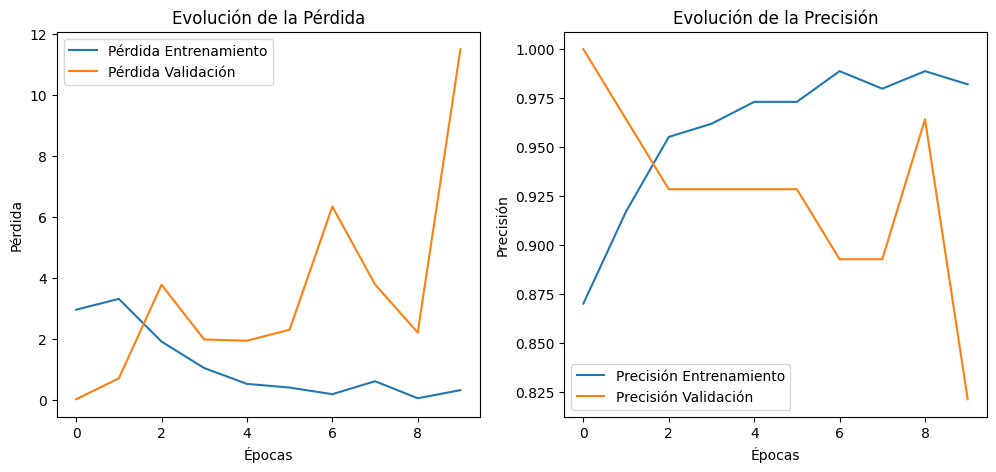

In [52]:
# 5. Cargar el modelo preentrenado sin la capa de clasificación
base_model = MobileNetV2(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

# Congelar las capas convolucionales del modelo base
for layer in base_model.layers:
    layer.trainable = False

# Construcción del nuevo modelo con capas personalizadas
model = Sequential([
    base_model,
    Flatten(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(len(train_data.class_indices), activation="softmax")  # Ajustar según el número de clases
])

# 6. Compilar el modelo
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

# 7. Entrenar el modelo
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

# 8. Evaluar el modelo en el conjunto de validación
test_loss, test_acc = model.evaluate(val_data)
acc_mobilenetv2 = test_acc
print(f"Precisión en validación MobileNetV2: {test_acc:.4f}")

# 9. Visualizar la evolución del entrenamiento
plt.figure(figsize=(12, 5))

# Pérdida
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Pérdida Entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida Validación')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.title('Evolución de la Pérdida')
plt.legend()

# Precisión
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Precisión Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Precisión Validación')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.title('Evolución de la Precisión')
plt.legend()

plt.show()


## 1. Comparación de Modelos

¿Cuál modelo obtuvo mejor precisión y por qué?
¿Cuánto tiempo de entrenamiento tomó cada modelo?


In [53]:
print(
    f"Precisión VGG16: {acc_vgg16:.4f}\n"
    f"Precisión InceptionV3: {acc_inceptionv3:.4f}\n"
    f"Precisión Mobile: {acc_mobilenetv2:.4f}\n"
)



Precisión VGG16: 0.8571
Precisión InceptionV3: 1.0000
Precisión Mobile: 0.9286

1.0000


La mayor precisión en este caso la obtuvo el modelo InceptionV3 con un 1.000

## 2. Conclusiones

¿El dataset elegido influenció el desempeño de los modelos?

R/ Sí, en este caso se eligió un dataset con solamente 2 categorías (perros y gatos) y u conjunto de imágenes relativamente pequeño (menos de 500 imágenes)

¿Qué ventajas ofrece Transfer Learning frente a entrenar una red desde cero?

R/ Evita tener que crear la red convolucional, además de que ya existe un preentrenamiento y dichos modelos ya están optimizados para extraer características específicas de ciertos problemas. Esto ahorra mucho tiempo de investigación y cómputo para proyectos que están empezando o no cuentan con el personal experimentado para entrenar el modelo.

¿Cómo podrían mejorarse los resultados con ajustes adicionales?

R/ Se podría empezar por aumentar el número de épocas específicadas, o añadiendo condiciones de parada de acuerdo a las métricas que se vayan obteniendo. Adicional a esto, se podría jugar con los hiperparámetros como el dropout, o las funciones de activación de las capas. Incluso, cambiar la forma de las capas fully connected al final de las capas del modelo base.